このファイルは2026年10月に李星達、菊池晃、岸元熙によって研究室内部の研究基盤用コードとして作成されました。

# Pythonを用いた反応動態シミュレーション

## **0. 本日の内容**

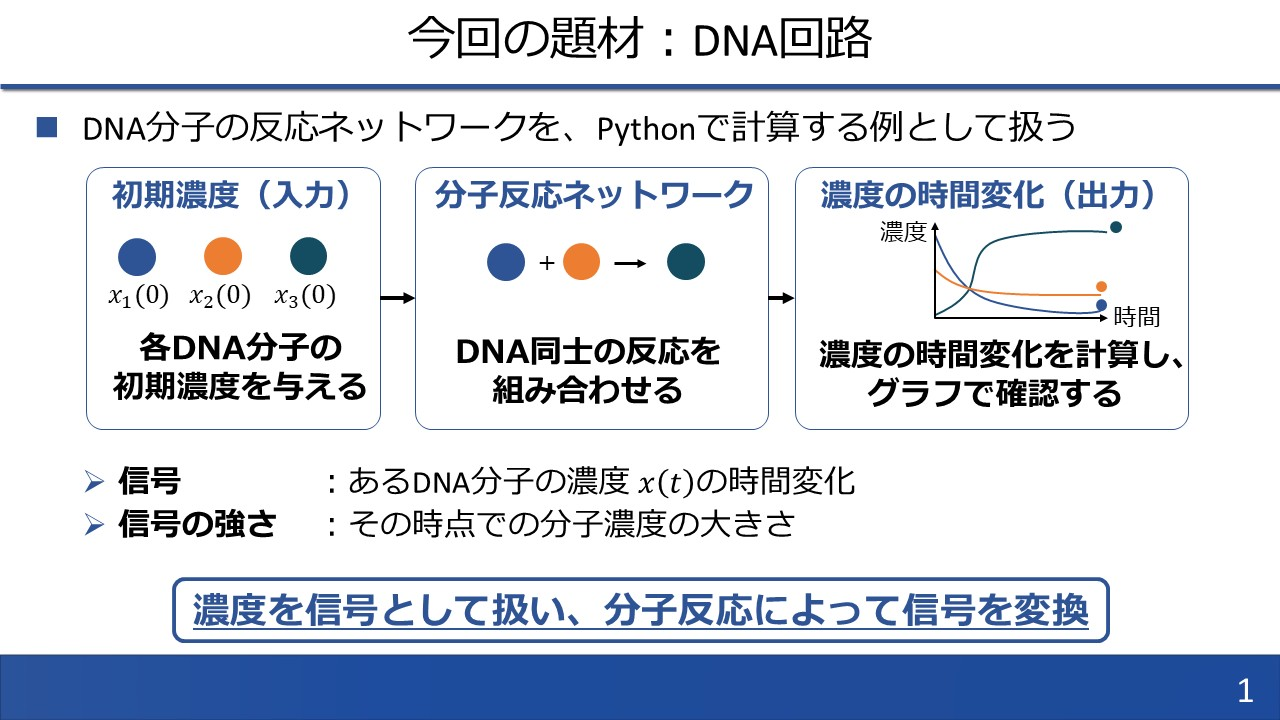
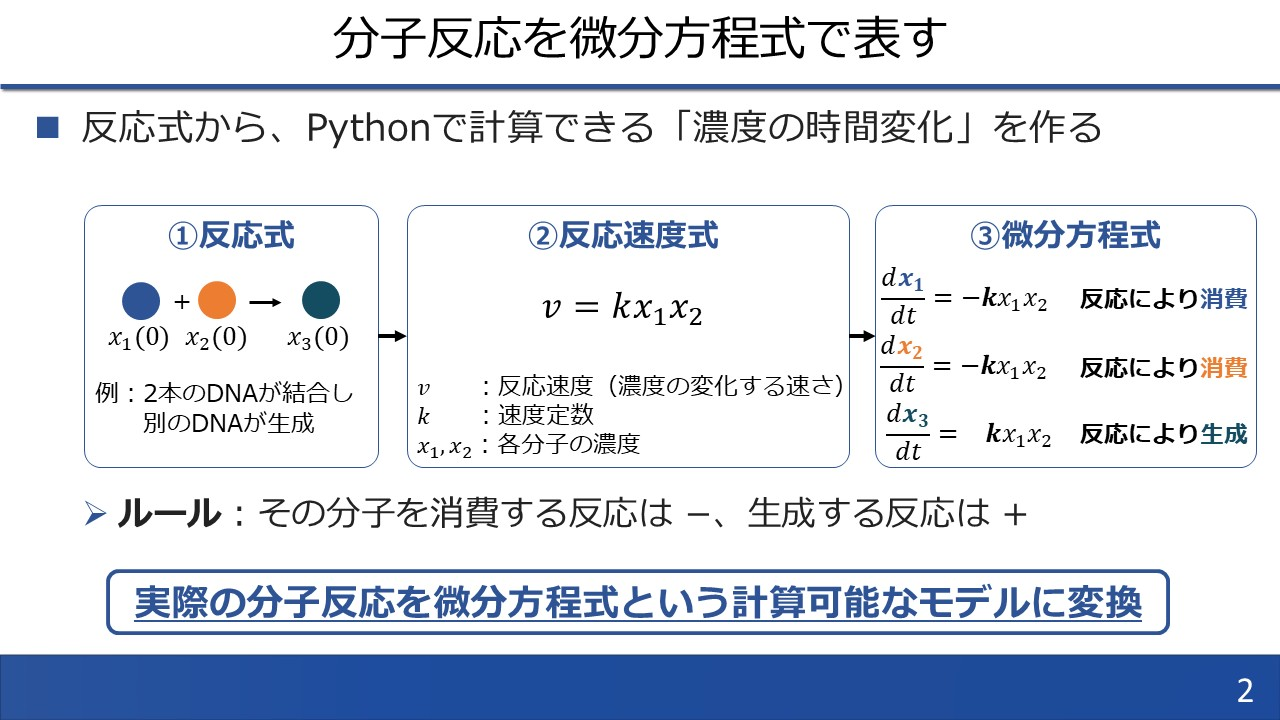
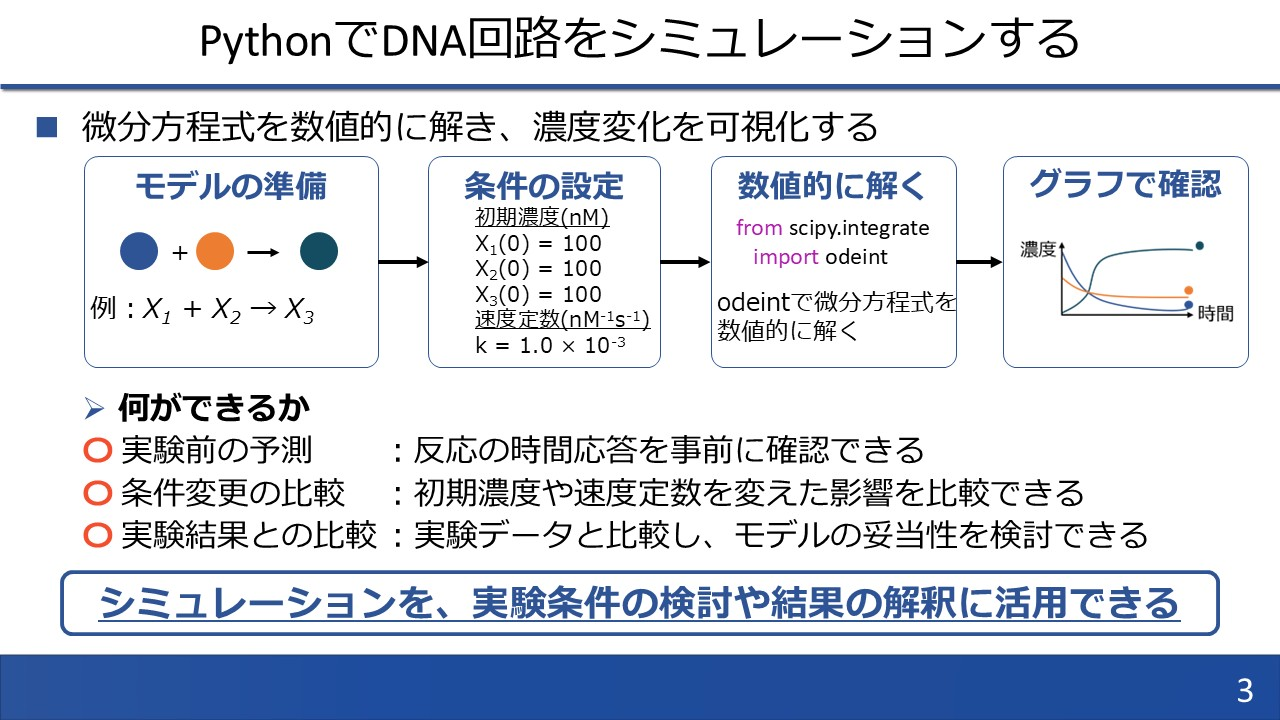

## **1. 導入**

### **1.1 本教材の対象**



* 化学反応のダイナミクス（動態、時間変化）のシミュレーションを行いたい方

* 数理モデルに基づくDNA回路の設計に興味がある方


### **1.2 本教材のゴール**
 * 化学反応のダイナミクスは微分方程式で表現できることを理解し、導出できるようになる
 * Pythonを用いて、DNA回路を含む化学反応のダイナミクスをシミュレーションできるようになる






### **1.3 目次**



1. **導入**

2. **化学反応と微分方程式**

3. **Pythonシミュレーションの基礎**

4. **練習:DNA回路のシミュレーション**

5. **DNA回路以外のシミュレーション**

6. **演習**

7. **発展：中間体のある反応を簡易モデルで書けるか**





####**1.4 本講義での注意点**
Google Colaboratoryのファイルを開いた際には必ず、ご自身のGoogle Driveに保存するようにしてください。

(内容を改変した場合、保存されない可能性があります。)

以下の画像を参考にして、ご自身のGoogle Driveにコピーを保存しましょう。

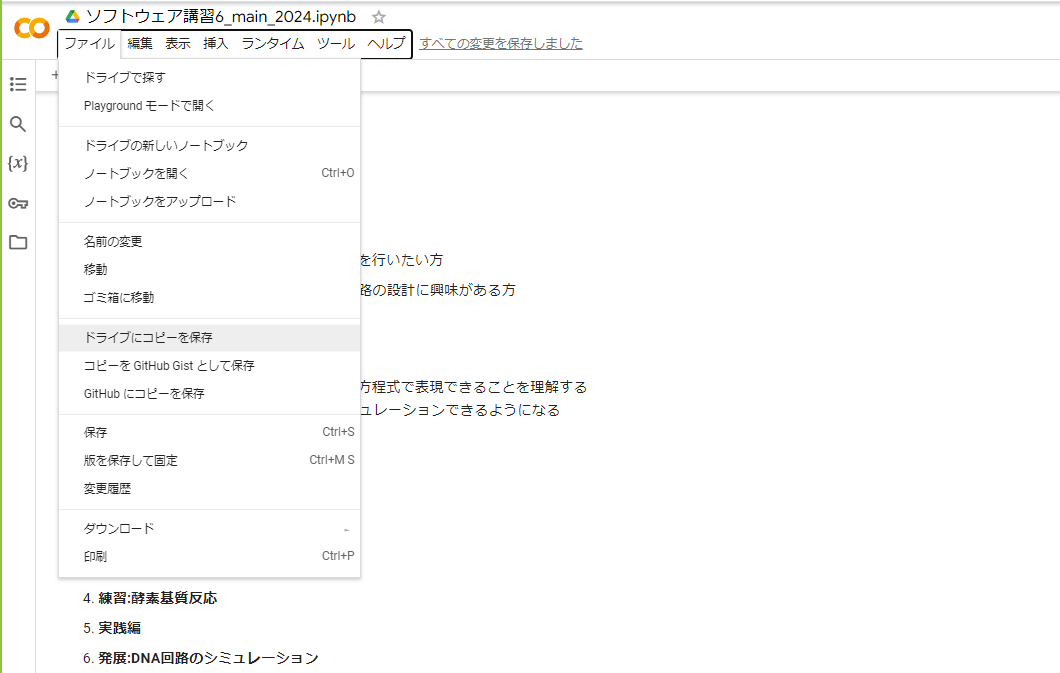

## **2. 化学反応と微分方程式**
本章ではPythonのシミュレーション方法の説明に入る前に、
化学反応のダイナミクスを微分方程式で立式するための考え方を紹介する。





### **2.1 反応速度論**
反応速度論とは、
様々な分子の相互作用によって引き起こる化学反応が、どのように時間変化していくのかを数学的に解析する物理化学の1つの分野である。

反応速度論では、化学反応が進行する速度「反応速度」を、その化学反応に関与する生体分子の「濃度」の関数で表現する。

「質量作用の法則」や「ミカエリス・メンテンの式」など、様々な表現方法があるが、解析の目的によって反応速度の適切な関数表現は変わる。



### **2.2 質量作用の法則**
本節では、反応速度論の中でも最も基本的な反応速度の表現方法である、質量作用の法則について説明する。
<br>
<br>
1つの化学反応を構成する分子は、大きく分けて①反応物②生成物の2種類に分類され、化学反応式の矢印を境に分かれる。
\begin{align}
\text{反応物}→\text{生成物}
\end{align}
反応物は化学反応の材料になる物質、生成物は化学反応が起きることで新しく作られる物質と、考えればよい。

質量作用の法則とは、 **「反応速度は反応物の濃度の積に比例する」** というルールのことを意味する。

具体例として、次の3つの化学反応の反応速度について考える。
<br>
<br>



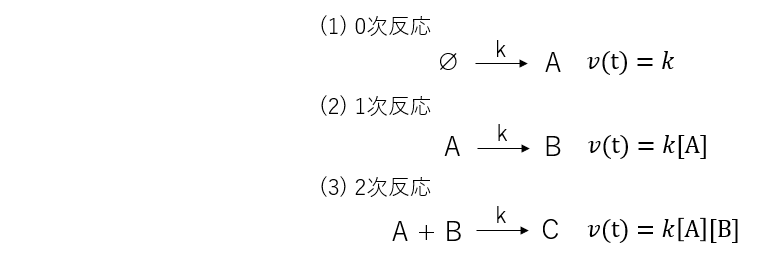


反応物の個数が$n$個の時、その反応を$n$次反応と呼ぶ。質量作用の法則に基づくと、$n$次反応の反応速度は濃度の$n$次関数となる。

1次反応である(2)は反応物が$A$のみであるため、その反応速度は$v(t) = k[A]$と表現できる。ここで、$[A]$は$A$の濃度、$k$は反応速度定数である。

同様に2次反応である(3)は、反応物が$A$と$B$の2つであるため、その反応速度は$v(t) = k[A][B]$と表現できる。

反応物が十分な量存在していて濃度が一定とみなせるとき、反応速度を定数で表現できる場合がある。このような反応を通例として0次反応と呼び、本資料では特定の反応物の代わりに記号$\varnothing$を用いて表す。

例えば(1)では、物質$A$が一定量の反応物から生成されるため、その反応速度を$v(t) = k$と表現できる。

**「反応物が存在せず、何もないところから物質が生まれる」** という意味ではないことに注意されたい。

### **2.3 DNA鎖の結合解離反応のダイナミクス**
前節で説明した質量作用の法則に基づいて、DNA鎖の結合・解離反応の微分方程式を立式する。

次の図はDNA鎖の結合・解離反応をモデル化したものである。

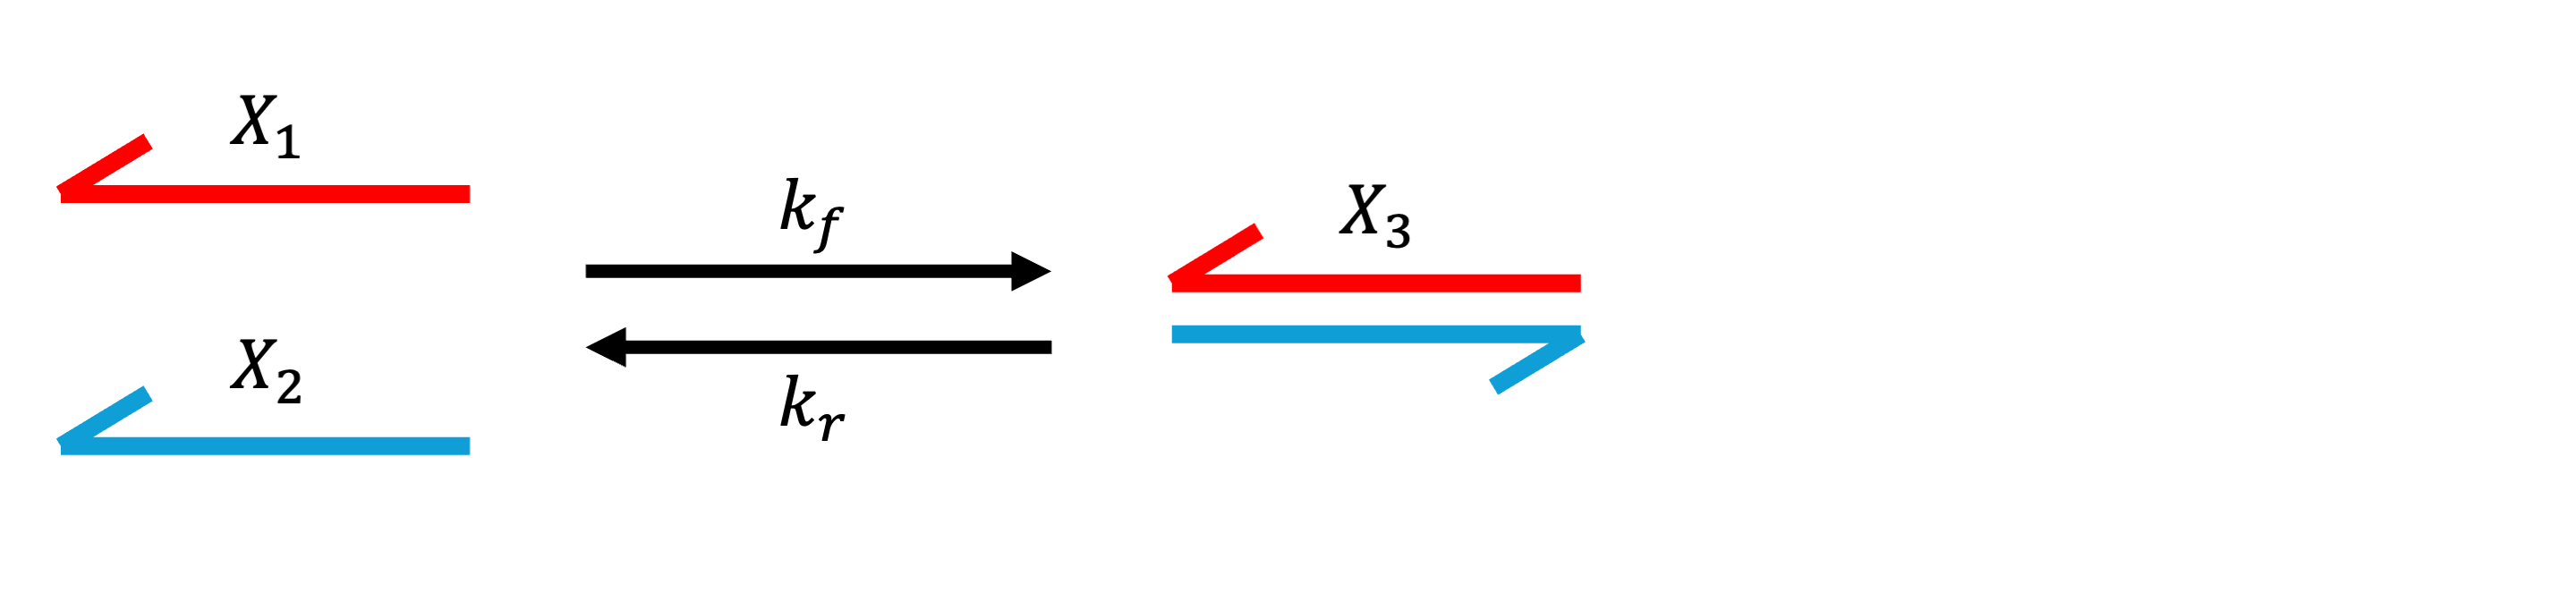

上図で示した結合解離反応の化学反応式は次のようになる。
\begin{align}
    X_1 + X_2 \overset{{\small{k_f}}}{{\longrightarrow}} X_3,\:
    X_3 \overset{{\small{k_r}}}{{\longrightarrow}}  X_1 + X_2
\end{align}

ここで、DNA鎖$X_1, X_2, X_3$の時刻$t$における濃度をそれぞれ$x_1(t), x_2(t), x_3(t)$とすると、質量作用の法則に基づき、各反応の時刻$t$における反応速度$v$は次のように表現できる。
\begin{align}
 & v_f(t) = k_f x_1(t) x_2 (t)\\
 & v_r(t) = k_r x_3(t)\\
\end{align}

ここで、$v_f(t)$が結合反応、$v_r(t)$が解離反応の反応速度である。

ある分子の濃度の時間変化は、 **[生成反応の反応速度の総和]-[消滅反応の反応速度の総和]** で決まる。
したがって、$x_1(t), x_2 (t), x_3(t)$の時間変化は次の微分方程式で書ける。

\begin{align}
  &\frac{dx_1(t)}{dt} = v_r(t) - v_f(t) =  k_r x_3(t) -  k_f x_1(t) x_2(t)\\
  &\frac{dx_2(t)}{dt} = v_r(t) - v_f(t) =  k_r x_3(t) -  k_f x_1(t) x_2(t)\\
  &\frac{dx_3(t)}{dt} = v_f(t) - v_r(t) = k_f x_1(t) x_2(t) - k_r x_3(t)
\end{align}

以上のように、ある化学反応のダイナミクスを表現する微分方程式は次の流れで導出できる。
1. **化学反応式を立式**
2. **反応速度論のルールに基づき反応速度を求める**
3. **[生成反応の反応速度の総和]-[消滅反応の反応速度の総和]を求める**

1と2には、どの物質まで考慮するのか、どのルールに従って反応速度を決めるのか、について自由度がある。

必ずしも生体分子や反応の種類を増やした、複雑で難しい微分方程式が正解というわけではなく、シンプルな微分方程式の方が化学反応系の本質的な特性を上手く表現していることもある。

目的に応じて、適切な情報量の微分方程式を導出することが重要である。





## **3. Pythonシミュレーションの基礎**
本章では、Pythonの基礎的な使い方と微分方程式のシミュレーション方法について説明する。

具体例として、前章で導出したDNA鎖の結合解離反応の微分方程式をシミュレーションするサンプルコードを示す。

Pythonの基本的なプログラミング方法をより詳しく知りたい方は以下のノートブックを参照されたい。

https://colab.research.google.com/drive/1LsdYb8UcrMJfr6J91DI3EXsG0Bb0F2Ow?usp=sharing

### **3.1 プログラムの実行とコメント記載方法**
##### **・プログラムの実行方法**
Google Colaboratory上でプログラムを実行する (動かす) 際は、プログラムが書かれているセル の左上にある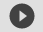
ボタンをクリックすることで実行することができる。
次のセルのコードを実行しなさい。

("Hello World!"と出力されれば、正常に実行されている)

<br>

##### **・ コメント記載方法**
Pythonで書かれたプログラムでは、 "#" を書くことで "#" 以下の内容はプログラムとして実行されず、コメントとして残すことができる。

In [ ]:
print("Hello World!")
#print("Python")

### **3.2 Pythonを用いた結合解離反応のシミュレーション**
本節では、ScipyというPythonのライブラリを用いて、微分方程式をシミュレーションする方法を紹介する。
Pythonには、様々な科学技術計算を効率化するライブラリ（道具箱のようなもの）が存在する。

その中でも「scipy」は、数式処理（積分、線形代数、数理最適化など）に強いライブラリである。

scipyのモジュールの一つである「scipy.integrate」には、微分方程式を数値計算的に解くことができる「odeint」という関数が存在し、微分方程式の定義、各変数の初期値や定数の設定をすることで、各変数の時間変化がシミュレーションできる

本講義ではこのツールを利用して化学反応のダイナミクスをシミュレーションする。



以下は、前章で導出したDNA鎖の結合解離反応の微分方程式をシミュレーションするサンプルコードである。

\begin{align}
  &\frac{dx_1(t)}{dt} = v_r(t) - v_f(t) =  k_r x_3(t) -  k_f x_1(t) x_2(t)\\
  &\frac{dx_2(t)}{dt} = v_r(t) - v_f(t) =  k_r x_3(t) -  k_f x_1(t) x_2(t)\\
  &\frac{dx_3(t)}{dt} = v_f(t) - v_r(t) = k_f x_1(t) x_2(t) - k_r x_3(t)
\end{align}

In [ ]:
#@title DNA鎖の結合解離反応

import numpy as np
import matplotlib.pyplot as plt
# 微分方程式を解くためのツールのインポート
from scipy.integrate import odeint

# 初期濃度
x0 = [10, 5, 0]

# 反応速度定数
k_f = 1
k_r = 1.5
# 時間を定義
t = np.linspace(0,5,1000)

# 解きたい微分方程式の定義
def odemodel(x, t, k_f,k_r):
    dxdt = [k_r*x[2] - k_f *x[0]*x[1],
            k_r*x[2] - k_f *x[0]*x[1],
            k_f *x[0]*x[1] -  k_r*x[2]]
    return dxdt


# 微分方程式を解かせる
x = odeint(odemodel, x0, t, args=( k_f,k_r))

# グラフの可視化
plt.plot(t,x)
plt.xlabel('time')
plt.ylabel('concentration')
plt.grid(True, linestyle='--', color='grey') #False
plt.legend(['$X_1$','$X_2$', '$X_3$'])
plt.rcParams["font.size"] = 24
plt.rcParams['font.family']= 'sans-serif' #'sans-serif'
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

今回使用した微分方程式を解くツール (scipy.integrate.odeint) について詳しく知りたい場合には、以下のサイトを参照されたい。
https://docs.scipy.org/doc/scipy/reference/integrate.html



### **3.3 視覚的にパラメタを変化させる方法**
前節のサンプルコードに数行コードを追加すると、
視覚的にパラメタを変化させるスライドバーを表示させることができる。

スライドバーを用いると、コード自体を編集することなく、パラメタを変化させたシミュレーションを簡単に行うことができる。

In [ ]:
#@title  DNA鎖の結合解離反応（スライドバー）
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
# 微分方程式を解くためのツールのインポート
from scipy.integrate import odeint

# 初期濃度
x0 = [10, 5, 0]

# 反応速度定数
k_f = 1 #@param {type:"slider", min:1, max:10, step:0.1}
k_r = 1 #@param {type:"slider", min:1, max:10, step:0.1}
# 時間を定義
t = np.linspace(0,5,1000)

# 解きたい微分方程式の定義
def odemodel(x, t, k_f,k_r):
    dxdt = [k_r*x[2] - k_f *x[0]*x[1],
            k_r*x[2] - k_f *x[0]*x[1],
            k_f *x[0]*x[1] -  k_r*x[2]]
    return dxdt


# 微分方程式を解かせる
x = odeint(odemodel, x0, t, args=( k_f,k_r))

# グラフの可視化
plt.plot(t,x)
plt.xlabel('time')
plt.ylabel('concentration')
plt.grid(True, linestyle='--', color='grey') #False
plt.legend(['$X_1$','$X_2$', '$X_3$'])
plt.rcParams["font.size"] = 24
plt.rcParams['font.family']= 'sans-serif' #'sans-serif'
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

Gooogle Colabratory上でスライドバーの設定方法について詳しく知りたい方は以下のサイトを参照されたい。
https://colab.research.google.com/notebooks/forms.ipynb

## **4. 練習：DNA回路のシミュレーション**
本章では前章までに説明した、質量作用の法則に基づく微分方程式の導出と、Pythonを用いたシミュレーションの練習問題として、いくつかのDNA回路反応を扱う。

###**4.1. 基本の鎖置換反応**
まずは単純な鎖置換反応を例題として、現象から実際にシミュレーションを行うまでの流れを追っていく。

以下のような一本鎖DNA$X_1$がゲートDNA$X_2$に結合する反応を考える。

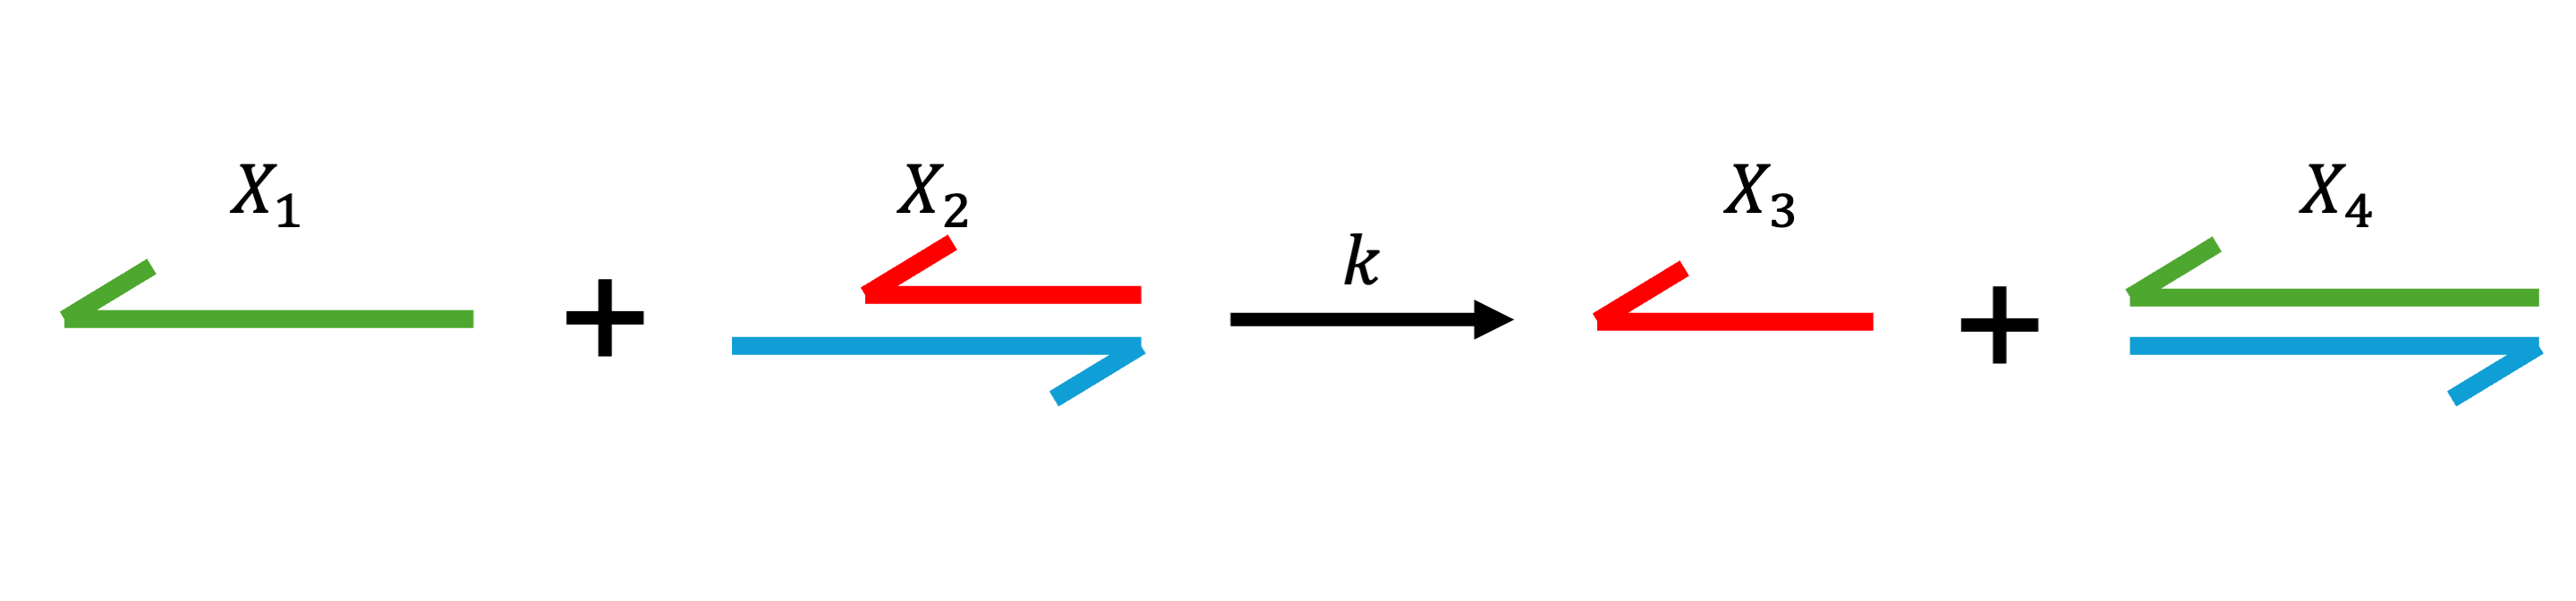

上図で示した結合解離反応の化学反応式は次のようになる。
\begin{align}
    X_1 + X_2 \overset{{\small{k}}}{{\longrightarrow}} X_3 + X_4
\end{align}
時刻$t$における各DNAの濃度を$x_1(t), x_2(t), x_3(t), x_4(t)$とすると質量作用の法則に基づき、この反応の時刻$t$における反応速度と、各DNAの濃度変化を表す微分方程式は次のように表現できる。
\begin{align}
 & v(t) = k x_1(t)x_2(t)\\
\end{align}

\begin{align}
  &\frac{dx_1}{dt} = -v(t) = -kx_1x_2 \\
  &\frac{dx_2}{dt} = -v(t) =-kx_1x_2 \\
  &\frac{dx_3}{dt} = v(t) = kx_1x_2 \\
  &\frac{dx_4}{dt} = v(t) = kx_1x_2 \\
\end{align}
ここで、$v(t)$は反応の速度を表している。

続いて、この連立微分方程式をpythonで実装してみよう。以下のコードは微分方程式を定義する部分だけ空白にしてある。3.2のコードを参考にして、空白を埋めてみよう。また、各DNAの初期濃度を変化させたときにどのような挙動の違いが見られるか確かめてみよう。

In [ ]:
#@title DNA strand displacement
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 各DNA種の初期濃度
x_1 = 5 #@param {type:"slider", min:0, max:10, step:0.1}
x_2 = 5 #@param {type:"slider", min:0, max:10, step:0.1}
x_3 = 0
x_4 = 0

# µM

#反応パラメータ
k = 0.005

x0 = [x_1, x_2, x_3, x_4]


# 時間を定義
t = np.linspace(0,10000,1000) #(start, end, points)

# 微分方程式を定義
def odemodel(x, t):
    dydt = [-k*x[0]*x[1], # この行がx1の微分方程式に対応する
            #########################
            ###　　　これより下を埋めよ      ###
            #########################

            # 空欄部分

            #########################
            ###　　　これより上を埋めよ     ###
            #########################
            ]
    return dydt

# 微分方程式を解かせる
x = odeint(odemodel,x0,t)

# グラフの描画
plt.plot(t,x)
plt.xlabel('time')
plt.ylabel('concentration (µM)')
plt.grid(':')
plt.legend(["$X_1$", "$X_2$", "$X_3$", "$X_4$"])
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

###**4.2. 反応数の多いDNA回路**
続いて、DNA回路における回路素子の１つであり、増幅器や論理計算回路としての役割が提案されているシーソーゲートについて扱う[2]。

反応の数が多くなりやや複雑に見えるかもしれないが、前節までと全く同じことをしているため、落ち着いて取り組んでほしい。


####**4.2.1 シミュレーションに向けたモデル化**
Pythonシミュレーションの準備として、まずはどのような反応が起きているのかモデルを立ててみよう。

反応の機序をどこまで厳密に考えるかは議論の余地があるが、今回は簡単のために中間状態を考慮しないモデルを考える。

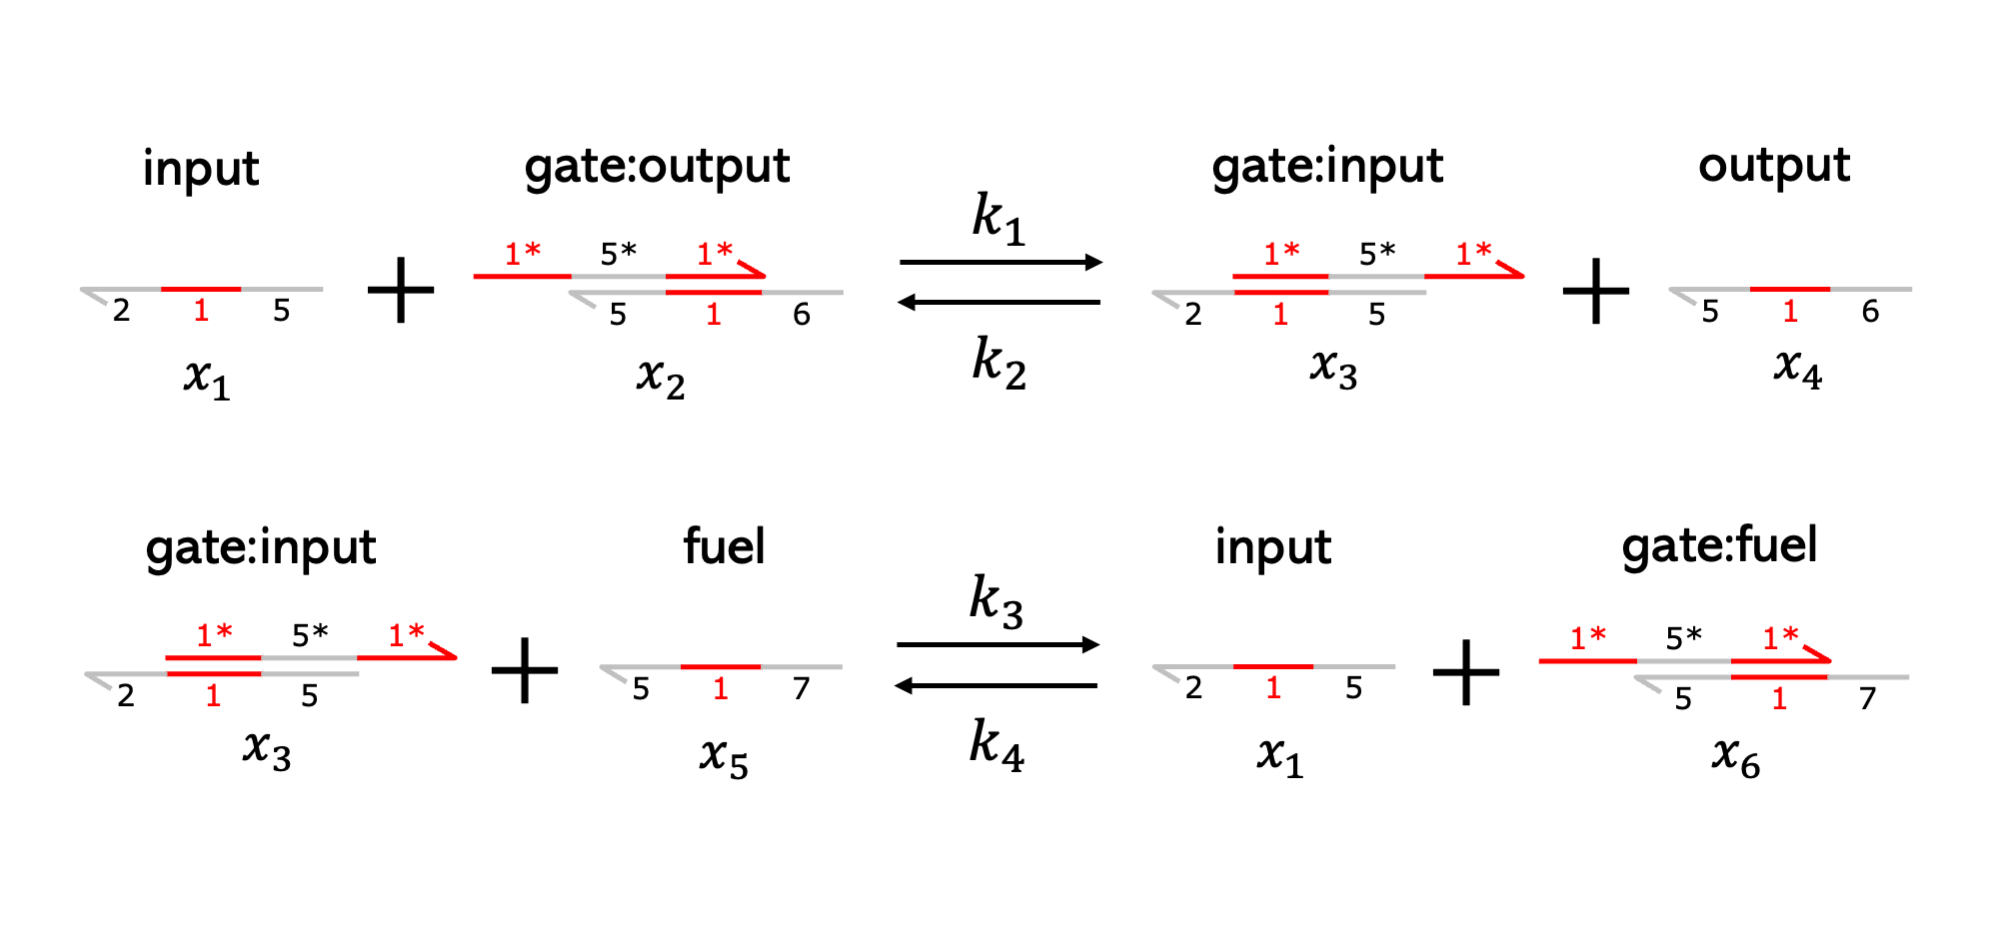

上図で示した結合解離反応の化学反応式は次のようになる。
\begin{align}
    X_1 + X_2 \overset{{\small{k_1}}}{{\longrightarrow}} X_3 + X_4,\:
    X_3 + X_4 \overset{{\small{k_2}}}{{\longrightarrow}} X_1 + X_2,\:
    X_3 + X_5 \overset{{\small{k_3}}}{{\longrightarrow}} X_1 + X_6,\:
    X_1 + X_6 \overset{{\small{k_4}}}{{\longrightarrow}} X_3 + X_5
\end{align}

時刻$t$における濃度を$x_1(t), x_2(t), x_3(t), x_4(t), x_5(t), x_6(t)$とすると、各DNA種のダイナミクスはどのような微分方程式で表せるだろうか？以下の式の空白部分を補ってみよう。

\begin{align}
  &\frac{dx_1}{dt} = -k_1x_1x_2 + k_2x_3x_4 + k_3x_3x_5 - k_4x_1x_6 \\
  &\frac{dx_2}{dt} =  \\
  &\frac{dx_3}{dt} =  \\
  &\frac{dx_4}{dt} =  \\
  &\frac{dx_5}{dt} = - k_3x_3x_5 + k_4x_1x_6 \\
  &\frac{dx_6}{dt} = k_3x_3x_5 - k_4x_1x_6 \\
\end{align}



####**4.2.2 Pythonを用いたシミュレーション**
微分方程式が非線形であり，また変数が多いこのような状況では、Pythonによるシミュレーションが有用である。
以下のpythonは微分方程式を定義する部分だけ空白にしてある。3.2のコードを参考にして、空白を埋めてみよう。

また、各DNA種の初期濃度を変えるとその挙動はどう変わるだろうか？例えば、より高い増幅率を達成するにはどうすればいいだろうか？

In [ ]:
#@title Seesaw gate
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 各DNA種の初期濃度
x_1 = 10 #@param {type:"slider", min:0, max:100, step:1}
x_2 = 10 #@param {type:"slider", min:0, max:100, step:1}
x_3 = 0
x_4 = 0
x_5 = 10 #@param {type:"slider", min:0, max:100, step:1}
x_6 = 0

# µM

# 反応パラメータ
k_1 = 0.0005
k_2 = 0.0005
k_3 = 0.0005
k_4 = 0.0005

x0 = [x_1, x_2, x_3, x_4, x_5, x_6]

# 時間を定義
t = np.linspace(0,10000,1000) #(start, end, points)

# 微分方程式を定義
def odemodel(x, t, k_1, k_2, k_3, k_4):
    dxdt = [-k_1*x[0]*x[1] + k_2*x[2]*x[3] + k_3*x[2]*x[4] - k_4*x[0]*x[5],
            #########################
            ###　　　これより下を埋めよ      ###
            #########################

            # 空欄部分

            #########################
            ###　　　これより上を埋めよ     ###
            #########################
            -k_3*x[2]*x[4] + k_4*x[0]*x[5],
            k_3*x[2]*x[4] - k_4*x[0]*x[5]]
    return dxdt

# 微分方程式を解かせる
x = odeint(odemodel, x0, t, args=(k_1,k_2,k_3,k_4))

# グラフの描画
plt.plot(t, x)
plt.xlabel('time')
plt.ylabel('concentration (µM)')
plt.grid(':')
plt.legend(["$X_1 (input)$", "$X_2 (gate:output)$", "$X_3 (gate:input)$", "$X_4 (output)$", "$X_5 (fuel)$", "$X_6 (gate:fuel)$"], fontsize=12)
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

## **5. DNA回路以外の生体分子反応**

DNA鎖置換反応以外にも生体分子で構成される反応系が多数存在する。
本節では例として酵素反応を扱うが、
反応の種類が違っても、数式を立ててシミュレーションを行うまでの手順は変わらない。

酵素は触媒作用を持つタンパク質であり、基質と結合した複合体を経由して生成物を合成する、という特徴がある。
次の図は酵素を$X_1$、基質を$X_2$、酵素と基質の複合物を$X_3$、生成物を$X_4$として、酵素反応をモデル化したものである。



###**5.1. 酵素反応**

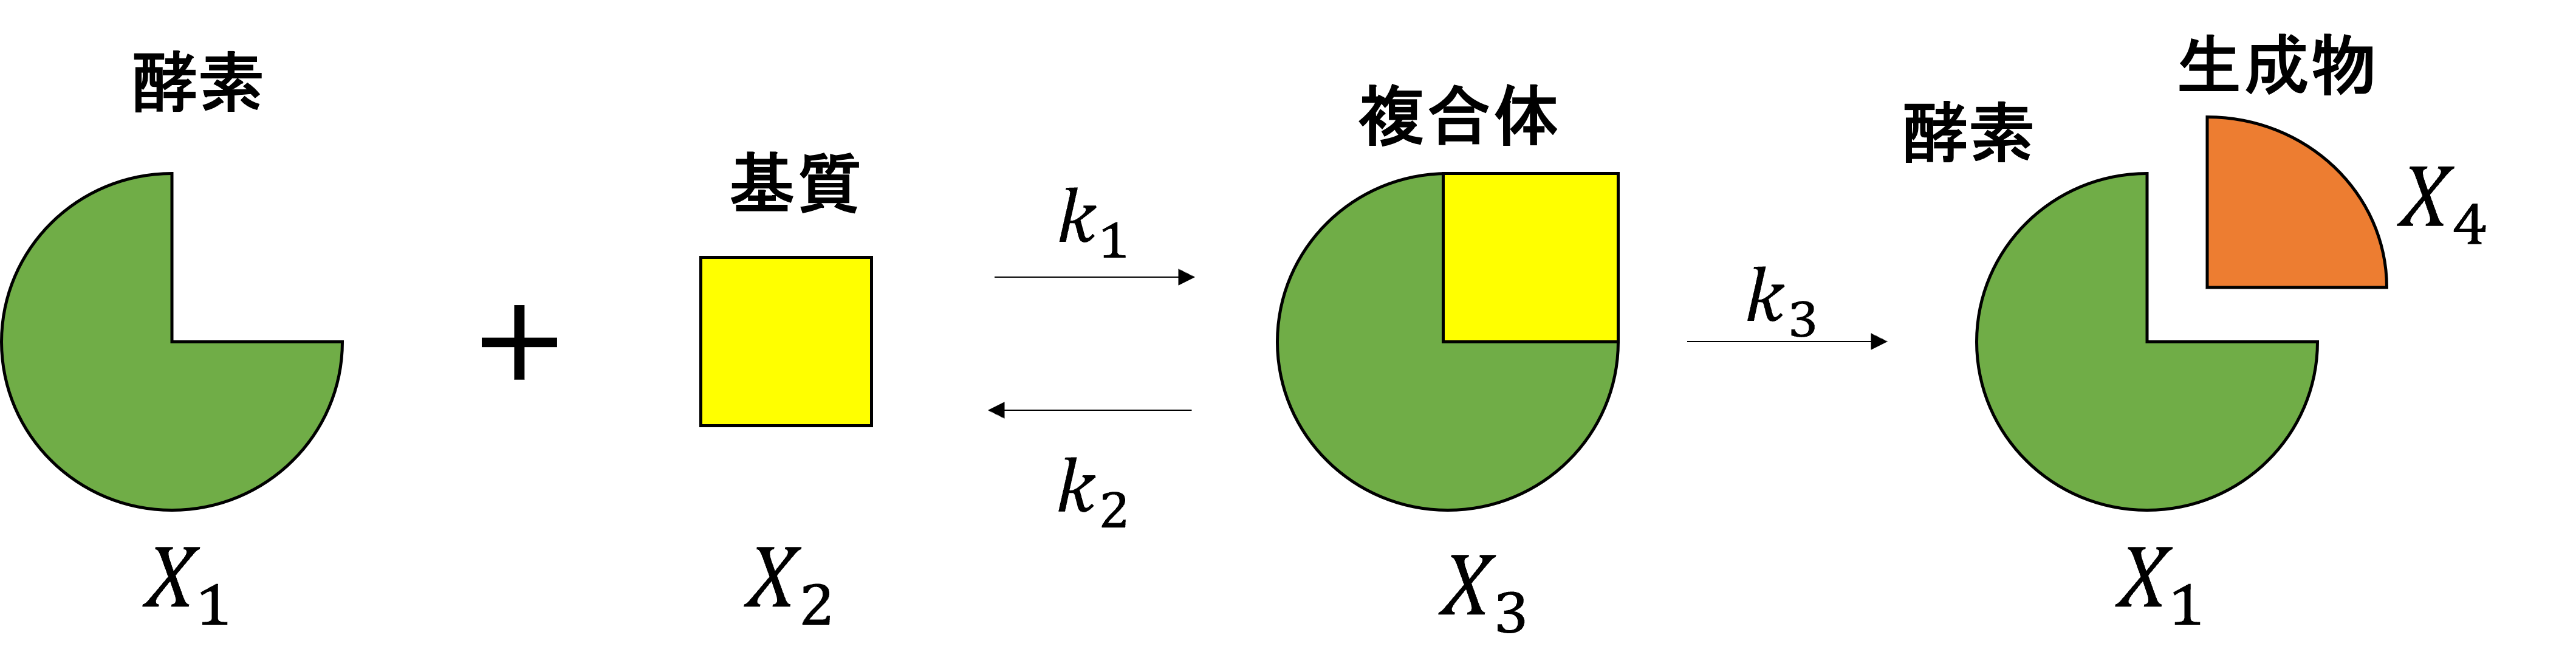

上図に基づき化学反応式を立式すると、次のようになる。
\begin{align}
    X_1 + X_2 \overset{{\small{k_1}}}{{\longrightarrow}} X_3,
    X_3 \overset{{\small{k_2}}}{{\longrightarrow}} X_1 + X_2,
    \ X_3 \overset{{\small{k_3}}}{{\longrightarrow}}  X_1 + X_4
\end{align}

酵素、基質、複合物、生成物の時刻$t$における濃度を$x_1(t), x_2(t),x_3(t), x_4(t)$とすると、質量作用の法則に基づき、各反応の時刻$t$における反応速度と、それぞれの微分方程式は次のように表現できる。

\begin{align}
 & v_1(t) = k_1x_1(t)x_2(t)\\
  & v_2(t) = k_2 x_3(t)\\
   & v_3(t) = k_3x_3(t)\\
\end{align}

\begin{align}
  &\frac{dx_1(t)}{dt} = v_2(t) + v_3(t) - v_1(t) = k_2 x_3(t) + k_3x_3(t) -  k_1x_1(t)x_2(t)\\
  &\frac{dx_2(t)}{dt} = v_2(t) - v_1(t) = k_2 x_3(t) -  k_1x_1(t)x_2(t)\\
  &\frac{dx_3(t)}{dt} = v_1(t) - v_2(t) - v_3(t) = k_1x_1(t)x_2(t) - k_2 x_3(t) - k_3x_3(t)\\
  &\frac{dx_4(t)}{dt} = v_3(t) = k_3x_3(t)
\end{align}

ここで、$v_1(t)$が結合反応、$v_2(t)$が解離反応、$v_3(t)$が生成物が生成される反応の反応速度である。


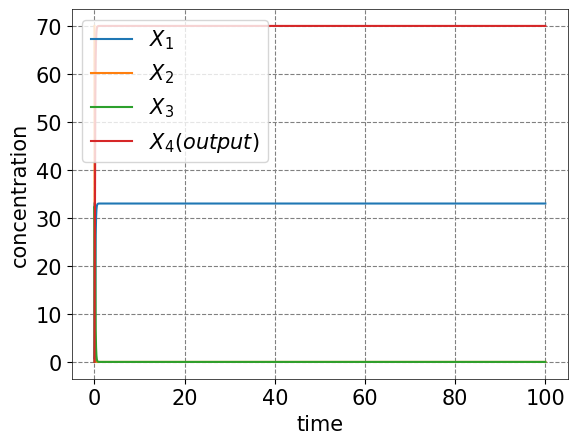

In [ ]:
#@title 酵素反応
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
# 微分方程式を解くためのツールのインポート
from scipy.integrate import odeint

# 初期濃度
x1_0 = 33#@param {type:"slider", min:1, max:100, step:1}
x2_0 = 70#@param {type:"slider", min:1, max:100, step:1}
x0 = [x1_0, x2_0, 0, 0]

# 反応速度定数
k_1 = 20
k_2 = 2
k_3 = 10

# 時間を定義
t = np.linspace(0,100,5000)

# 解きたい微分方程式の定義
def odemodel(x, t, k_1,k_2,k_3):
    dxdt = [k_2*x[2] + k_3*x[2]- k_1*x[0]*x[1],
            k_2*x[2] - k_1*x[0]*x[1],
            k_1*x[0]*x[1] - k_2*x[2] - k_3*x[2],
            k_3*x[2]]
    return dxdt


# 微分方程式を解かせる
x = odeint(odemodel, x0, t, args=(k_1,k_2,k_3))

# グラフの可視化
plt.plot(t,x)
plt.xlabel('time')
plt.ylabel('concentration')
plt.grid(True, linestyle='--', color='grey') #False
plt.legend(['$X_1$','$X_2$','$X_3$','$X_4 (output)$'])
plt.rcParams["font.size"] = 15
plt.rcParams['font.family']= 'sans-serif' #'sans-serif'
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

## **6. 演習**


### **6.1 DNA鎖を用いたAND回路のシミュレーション**
DNA鎖を用いたAND回路のシミュレーションに際して、論理回路の一種であるAND回路について紹介する。

AND回路は2入力1出力の回路で、2つの入力が共に1（濃度が高い状態）のとき (11の時) のみ出力が1となり、その他の入力 (00, 10, 01) に対しては、出力が0になるという特徴を有する論理回路である。

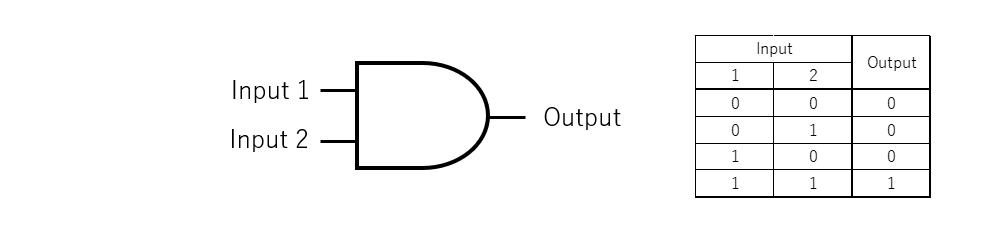

#### DNA AND回路の反応モデル

文献[3]を参考に、本教材ではDNA AND回路をInput 1、Input 2、Outputの3つの反応に簡略化して扱う。

##### Input 1

$$
X_{in_1} + X_{11}
\underset{k_{r1}}{\overset{k_{f1}}{\rightleftharpoons}}
X_{12} + X_{13}
$$

##### Input 2

$$
X_{in_2} + X_{21}
\underset{k_{r2}}{\overset{k_{f2}}{\rightleftharpoons}}
X_{22} + X_{23}
$$

##### Output

$$
X_{13} + X_{23} + X_{31}
\overset{k_{f3}}{\longrightarrow}
X_{out} + X_{32} + X_{33}
$$

Input 1の反応によって中間生成物 $X_{13}$ が生成され、Input 2の反応によって中間生成物 $X_{23}$ が生成される。

Output反応には $X_{13}$ と $X_{23}$ の両方が必要である。そのため、Input 1とInput 2の両方が存在するときにのみ $X_{out}$ が生成され、この反応モデルはAND回路として機能する。

| 変数 | 役割 |
|---|---|
| $X_{in_1}$ | Input 1 |
| $X_{in_2}$ | Input 2 |
| $X_{13}$ | Input 1から生成される中間生成物 |
| $X_{23}$ | Input 2から生成される中間生成物 |
| $X_{31}$ | Output反応に必要なDNA種 |
| $X_{out}$ | AND回路の出力 |

このDNA回路の微分方程式は以下で与えられる。


####input_1
\begin{align}
&\frac{d x_ {in\_1}}{dt} = -k_{f1} x_{in\_1} x_{11} + k_{r1} x_{12} x_{13}\\
&\frac{d x_{11}}{dt} = -k_{f1} x_{in\_1} x_{11} + k_{r1} x_{12} x_{13}\\
&\frac{d x_{12}}{dt} = k_{f1} x_{in\_1} x_{11} - k_{r1} x_{12} x_{13}\\
&\frac{d x_{13}}{dt} = k_{f1} x_{in\_1} x_{11} - k_{r1} x_{12} x_{13}\\
&\end{align}



#### input_2
\begin{align}
&\frac{d x_ {in\_2}}{dt} = - k_{f2} x_{in\_2} x_{21} + k_{r2} x_{22} x_{23}\\
&\frac{d x_{21}}{dt} = -k_{f2} x_{in\_2} x_{21} + k_{r2} x_{22} x_{23}\\
&\frac{d x_{22}}{dt} = k_{f2} x_{in\_2} x_{21} - k_{r2} x_{22} x_{23}\\
&\frac{d x_{23}}{dt} = k_{f2} x_{in\_2} x_{21} - k_{r2} x_{22} x_{23}\\
&\end{align}

#### output
\begin{align}
&\frac{d x_ {13}}{dt} = -k_{f3} x_{13} x_{23} x_{31}\\
&\frac{d x_ {23}}{dt} = -k_{f3} x_{13} x_{23} x_{31}\\
&\frac{d x_ {31}}{dt} = -k_{f3} x_{13} x_{23} x_{31}\\
&\frac{d x_ {out}}{dt} = k_{f3} x_{13} x_{23} x_{31}\\
&\frac{d x_ {32}}{dt} = k_{f3} x_{13} x_{23} x_{31}\\
&\frac{d x_ {33}}{dt} = k_{f3} x_{13} x_{23} x_{31}
&\end{align}
</div>

以下は上記の微分方程式における$x_ {in\_1}$、$x_ {in\_2}$および$x_{out}$の時間変化をシミュレートするコードである。空欄に当てはまるコードを書いて提出せよ。（ヒント：空欄部分はinput_2に相当する。）また、完成させたシミュレーションにおいて、パラメータを動かすことによって、入力が01、10、11の場合の出力はどうなるか。シミュレーション結果の画像を提出すると共に、その画像を用いて入出力関係について説明せよ。

(シミュレーション結果のグラフを右クリックし、"画像をコピー"を選択すると画像をコピーできる。)




問題を解く際には、ベクトル$x$を以下のように考えれば良い。また，上記の微分方程式中で、$x_{13}$および$x_{23}$が2回現れていることに注意されたい。
\begin{equation}
 x = [x_{in\_1}, x_{11}, x_{12}, x_{13}, x_{in\_2}, x_{21}, x_{22}, x_{23}, x_{31}, x_{out}, x_{32}, x_{33}]
\end{equation}

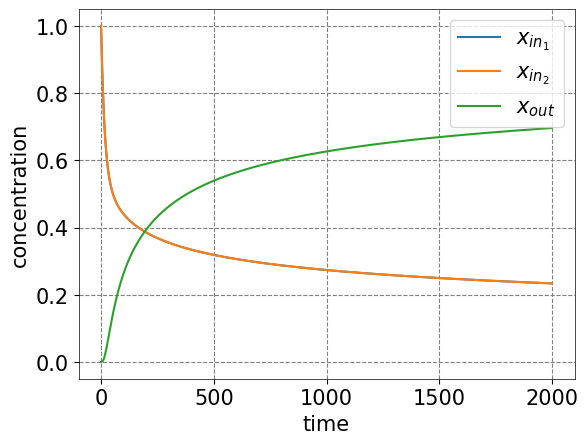

In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt


#反応速度定数
k_f1 = k_f2 = k_f3 = 0.03
k_r1 = k_r2 = k_r3 = 0.03


#@title AND{ run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

#DNA鎖の初期濃度
x_in1 = 1 #@param {type:"slider", min:0, max:1, step:1}
x_in2 = 1 #@param {type:"slider", min:0, max:1, step:1}

x_out = x_32 = x_33 = 0
x_12 = x_22 = x_13 = x_23 = 0
x_31 = x_11 = x_21 = 1

# 初期濃度をまとめたベクトル
x0 = [x_in1, x_11, x_12, x_13, x_in2, x_21, x_22, x_23, x_31, x_out, x_32, x_33]



# 時間を定義
t = np.linspace(0,2000,1000) #(start, end, points)

# 微分方程式を定義
def odemodel(x, t, k_f1, k_r1, k_f2, k_r2, k_f3, k_r3):
    dxdt = [-k_f1 * x[0] * x[1] + k_r1 * x[2] * x[3],
            -k_f1 * x[0] * x[1] + k_r1 * x[2] * x[3],
            k_f1 * x[0] * x[1] - k_r1 * x[2] * x[3],
            k_f1 * x[0] * x[1] - k_r1 * x[2] * x[3] - k_f3 * x[3] * x[7] * x[8],
            #########################
            ###　　　これより下を埋めよ      ###
            #########################

            # 空欄部分

            #########################
            ###　　　これより上を埋めよ     ###
            #########################
            -k_f3 * x[3] * x[7] * x[8],
            k_f3 * x[3] * x[7] * x[8],
            k_f3 * x[3] * x[7] * x[8],
            k_f3 * x[3] * x[7] * x[8]]

    return dxdt

# 微分方程式を解かせる
model = lambda x,t: odemodel(x, t, k_f1, k_r1, k_f2, k_r2, k_f3, k_r3)



# 微分方程式を解かせる
x  = odeint(model,x0,t).T


# グラフの描画
plt.plot(t, x[0], label = "$x_{in_1}$")
plt.plot(t, x[4], label = "$x_{in_2}$")
plt.plot(t, x[9], label = "$x_{out}$")
plt.xlabel('time')
plt.ylabel('concentration')
plt.grid(True, linestyle='--', color='grey')
plt.legend()
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

###**6.2. DNAコンパレータ**
本講義で説明した質量作用の法則を用いて、反応モデルから微分方程式を定式化してみよう。
本問題ではDNA鎖濃度の擬似的な引き算を行う、DNAコンパレータについて扱う。
DNAコンパレータは、2種のDNA鎖の濃度を比較し、どちらの濃度が高いかに応じて異なる出力を返す回路素子である。本教材では、文献[4]を参考に、その動作を簡略化した反応モデルを用いて扱う。

#### **6.2.1 DNAコンパレータのモデル**
次の図は、上記の簡略化に基づき、DNAコンパレータの各反応をモデル化したものである。簡単のため、ダイナミクスを考える上で重要でないDNA種は省略し、各DNA種をそれぞれ $X_1, X_2, X_3, X_4, X_5, X_6$ と置いている。$X_1$および$X_4$が回路への入力、$X_3$および$X_6$が回路からの出力に相当する。

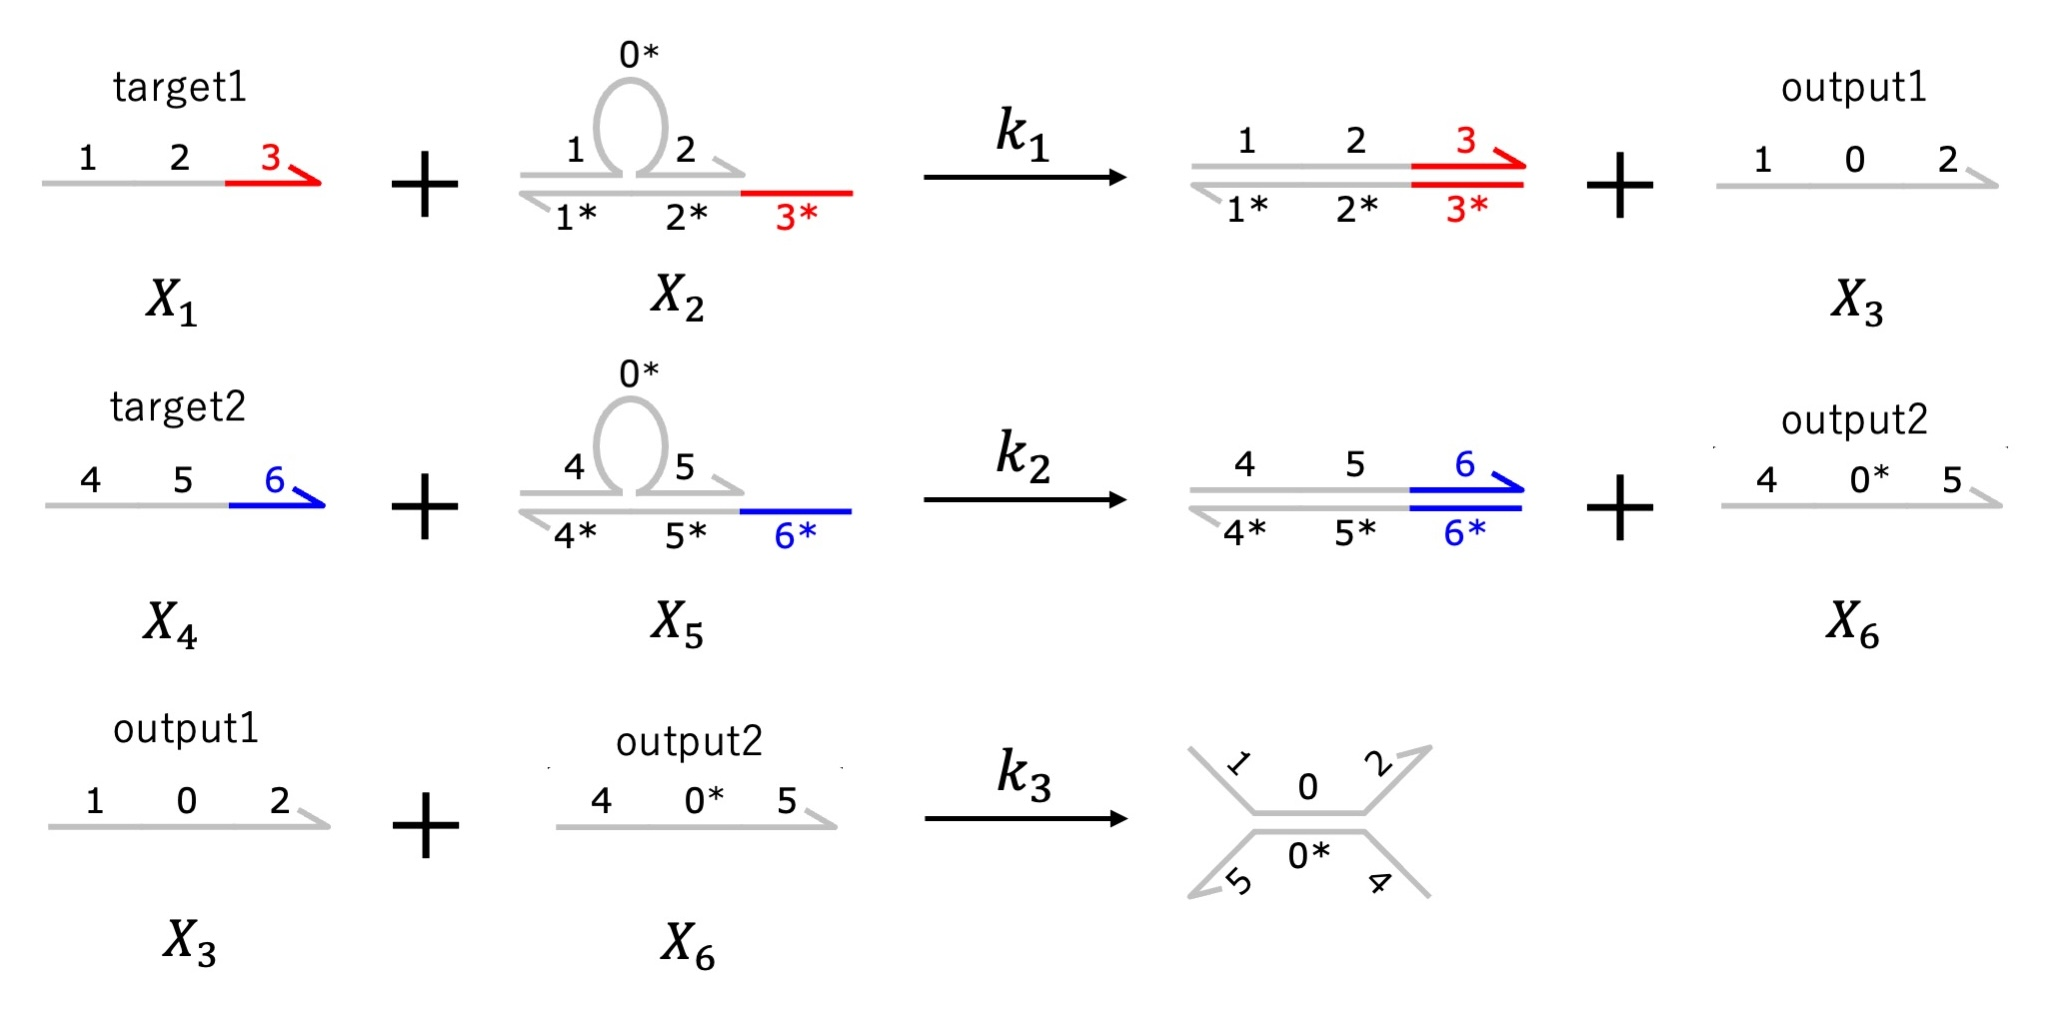

それぞれの化学反応式は、反応速度定数$k_1, k_2, k_3$を用いると、以下のように書くことができる。
\begin{align}
    X_1 + X_2 \overset{{\small{k_1}}}{{\longrightarrow}} X_3,
    \:X_4 + X_5 \overset{{\small{k_2}}}{{\longrightarrow}} X_6,
    \:X_3 + X_6\overset{{\small{k_3}}}{{\longrightarrow}} \varnothing
\end{align}
ただし$\varnothing$は重要でないDNA種を表す。

濃度の時間変化を表す微分方程式はどのように表されるか。以下の各微分方程式の右辺に相当する式を、反応速度定数$k_1, k_2, k_3$および$x_1(t), x_2(t), x_3(t), x_4(t), x_5(t), x_6(t)$を用いて答えよ。

\begin{align}
  &\frac{dx_1(t)}{dt} =  -k_1x_1x_2 \\
  &\frac{dx_2(t)}{dt} =  \\
  &\frac{dx_3(t)}{dt} =  \\
  &\frac{dx_4(t)}{dt} =  \\
  &\frac{dx_5(t)}{dt} =  \\
  &\frac{dx_6(t)}{dt} =  \\
\end{align}


#### **6.2.2 DNAコンパレータにおける微分方程式のシミュレーション**
本講義で示したコードを参考に、$x_2(t)$〜$x_6(t)$の時間変化をシミュレートする以下のコード中にある空欄を埋め、出力されるグラフを提出せよ。なお、パラメータは適当な値で良い。(シミュレーション結果のグラフを右クリックし、"画像をコピー"を選択すると画像をコピーできる。)

また、理想的には、あらゆる入力の組み合わせに対してDNAコンパレータの出力は常に１種類であることが望ましい。このような理想特性に近づけるにはどのようにパラメータを設定すれば良いか考察せよ。パラメータを変えてシミュレーションを行い、そのパラメータに設定した理由と出力されるグラフを提出せよ。
また、反応パラメータを変えることは実際のDNA回路におけるどのような変化と対応するか考察せよ。

In [ ]:
#@title DNA comparator
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 各DNA種の初期濃度
x_1 = 10 #@param {type:"slider", min:0, max:10, step:0.5}
x_2 = 15
x_3 = 0
x_4 = 5 #@param {type:"slider", min:0, max:10, step:0.5}
x_5 =  15
x_6 = 0

# µM

#反応パラメータ
k_1 = 0.0001 #@param {type:"slider", min:0.00001, max:0.001, step:0.00001}
k_2 = 0.0001 #@param {type:"slider", min:0.00001, max:0.001, step:0.00001}
k_3 = 0.0001 #@param {type:"slider", min:0.00001, max:0.001, step:0.00001}

x0 = [x_1, x_2, x_3, x_4, x_5, x_6]


# 時間を定義
t = np.linspace(0,10000,1000) #(start, end, points)

# 微分方程式を定義
def odemodel(x, t):
    dydt = [-k_1*x[0]*x[1],
            #########################
            ###　　　これより下を埋めよ      ###
            #########################

            # 空欄部分

            #########################
            ###　　　これより上を埋めよ     ###
            #########################
            ]
    return dydt

# 微分方程式を解かせる
y = odeint(odemodel,x0,t)

# グラフの描画
plt.plot(t,y)
plt.xlabel('time')
plt.ylabel('concentration (µM)')
plt.grid(':')
plt.legend(["$X_1 (target1)$", "$X_2$", "$X_3 (output1)$", "$X_4 (target2)$", "$X_5$", "$X_6 (output2)$"])
plt.rcParams['axes.facecolor'] = 'white'
plt.show()

## **7. 発展：中間体のある反応を簡易モデルで書けるか**

これまで鎖置換反応は1つの反応として扱ってきた．しかし途中にできる中間体まで考慮した，より細かいモデルを立てることもできる．この節ではそれを用いて，今までのモデルが妥当な条件を考える．

### **7.1 中間体を考慮したモデル**

入力鎖が基質に結合してから既存鎖が出力されるまでには，入力鎖がトーホールドで結合しただけの状態がある．この状態を中間体として考慮すると下図のモデルになる．これを詳細モデルと呼ぶ．
一方で，6節までのモデルは中間体を考慮せず，結合から置換の完了までを1つの反応と1つの速度定数でまとめて表していた．以下ではこれを簡易モデルと呼ぶ．

詳細モデルを使うには速度定数が3つ必要になる．実験で測定するのは一般に，出力される既存鎖（下図:$X_4$）の濃度の時間変化であり，そこから3つの速度定数を個別に決めるのは難しい．
簡易モデルであれば，速度定数は1つだけであり，出力される既存鎖の濃度の時間変化へのフィッティングにより求めることができる．この点で，簡易モデルは詳細モデルより扱いやすい．

以下では2つのモデルをそれぞれ微分方程式で書き（7.2），簡易モデルが妥当になる条件を示したうえで（7.3），2つのモデルのシミュレーションから考察をしよう（7.4）．

スライド1.SVG

### **7.2 詳細モデルと簡易モデルの微分方程式**

**詳細モデル**  

詳細モデルを反応式で書くと次のようになる．

$$X_1+X_2 \underset{k_{-1}}{\overset{k_1}{\rightleftharpoons}} X_3 \overset{k_2}{\longrightarrow} X_4+X_5$$

$X_1$ は入力鎖，$X_2$ は基質，$X_3$ は入力鎖が基質にトーホールドで結合した中間体，$X_4$ は反応で出力される既存鎖，$X_5$ は入力鎖が組み込まれてできる新しい二本鎖である．実験では $X_4$ の量を測定する．入力鎖 $X_1$ は基質 $X_2$ より十分多く加えて，反応で消費されても濃度 $x_1$ がほとんど変わらないとする．

時刻 $t$ における濃度を $x_1, \dots, x_5$ と書くと，質量作用の法則から

\begin{align}
  &\frac{dx_2}{dt} = -k_1 x_1 x_2 + k_{-1} x_3 \\
  &\frac{dx_3}{dt} =  k_1 x_1 x_2 - (k_{-1} + k_2)\, x_3 \\
  &\frac{dx_4}{dt} =  k_2 x_3
\end{align}

を得る．

**簡易モデル**  
簡易モデルの反応式は

\begin{align}
    X_1 + X_2 \overset{{\small{k_\text{eff}}}}{\longrightarrow} X_4 + X_5
\end{align}

であり，4.2 で使ったのはこの形である．質量作用の法則から

\begin{align}
\frac{dx_4}{dt} = k_\text{eff}\, x_1\, x_2
\end{align}

となる．

ここで，基質$X_2$の濃度 $x_2$ は実験で直接には測れない．実験で追えるのは $X_4$ の濃度 $x_4$ である．そこで，この式を測れる量で書き直す．簡易モデルでは，既存鎖（7.1の図：赤色DNA鎖）は基質 $X_2$ の中にあるか，押し出されて $X_4$ になっているかのどちらかである．したがって，基質の初期濃度を $s_0$ とすると $x_2 + x_4 = s_0$ が成り立つ．これを代入すると

\begin{align}
\frac{dx_4}{dt} = k_\text{eff}\, x_1\, (s_0 - x_4)
\end{align}

を得る．右辺に現れるのは，加えた量 $x_1$ と $s_0$，測定される $x_4$，速度定数 $k_\text{eff}$ だけである．

**2つのモデルの違い**  
詳細モデルでは既存鎖は $X_2$，$X_3$，$X_4$ のいずれかに含まれるので，$s_0 - x_4 = x_2 + x_3$ である．つまり簡易モデルが基質として扱っている $s_0 - x_4$ には，中間体 $X_3$ の分も含まれている．この違いを無視してよいか，すなわち簡易モデルが妥当かどうかの目安が，次の 7.3 の $\varepsilon$ である．

### **7.3 簡易モデルが妥当な条件**
簡易モデルで妥当かどうかの目安になるのが，次の量 $\varepsilon$ である（詳しい導出は7.6参照）．

\begin{align}
\varepsilon = \frac{k_1 x_1}{k_{-1} + k_2}
\end{align}

簡易モデルが妥当な条件は $\varepsilon \ll 1$ である．分子の $k_1 x_1$ は中間体 $X_3$ に入る起こりやすさ，分母の $k_{-1} + k_2$ は $X_3$ から出ていく起こりやすさである．


蛇口から水を注ぎながら排水口の栓を抜いている状況にたとえると，$k_1 x_1$ が蛇口の勢い，$k_{-1} + k_2$ が排水口の太さ，水位は中間体 $X_3$ の量にあたる．排水口の太さは DNA の配列で決まり，同じ DNA 分子なら変わらない．蛇口の勢いに比べて排水口が十分太ければ，注ぎ続けても水位は低いままである．$\varepsilon \ll 1$ はこの状態にあたり，中間体 $X_3$ はほとんど溜まらない．入力鎖を濃くすることは，蛇口をひねって勢いを強めることにあたり，このとき水位は上がっていってしまう．すなわち，中間体$X_3$が溜まっていってしまう状況に相当する．

7.2 で見たように，簡易モデルは中間体 $X_3$ の分も区別せずに基質として数えている．$\varepsilon \ll 1$ なら $X_3$ はごくわずかとなり，この違いは無視できる．$\varepsilon$ が大きいと無視できない量の基質が $X_3$ として留まり，簡易モデルは反応を詳細モデルより速く進むと見積もってしまう．


**入力鎖の濃度が高い場合**  
質量作用の法則で速度式を立てるとき，速度定数は濃度によらない定数として扱う．ところが $\varepsilon$ は入力鎖の濃度 $x_1$ に比例するので，入力鎖の濃度を高くすると $\varepsilon$ は大きくなってしまう．濃度が高すぎると $\varepsilon \ll 1$ の条件が破れて簡易モデルは妥当でなくなり，ある濃度で求めた $k_\text{eff}$ を別の濃度でそのまま使うことはできなくなってしまう．

なお $\varepsilon$ は分子によっても異なり，トーホールドが長い分子ほど入力鎖が外れにくく（$k_{-1}$ が小さく），同じ濃度でも $\varepsilon$ は大きくなる（7.4 発展課題）．

### **7.4 デモ：$\varepsilon$ と簡易モデルの破れ**

次のセルは詳細モデルを解き，簡易モデル $dx_4/dt = k_\text{eff}\, x_1 (s_0 - x_4)$ の解を重ねて描く．スライダーで動かすのは入力鎖の濃度 $x_1$ だけで，$k_1$，$k_{-1}$，$k_2$，$s_0$ は固定している．$x_1$ を動かすことは，同じ分子のまま，加える入力鎖の量を変えて実験をやり直すことにあたる（$x_1$ は1回の実験の中では一定とみなす量である）．

**グラフの見方**
- 上段：縦軸は $x_4 / s_0$，すなわち反応を終えた基質の割合である．実線が詳細モデル，破線が簡易モデルで，2本が重なるかどうかは，$k_\text{eff}$ を代入した簡易モデルが詳細モデルと合うかどうかを表す
- 下段：縦軸は $x_3 / s_0$，すなわち中間体 $X_3$ として留まっている基質の割合である

In [ ]:
#@title 7.4 デモ（スライドバー）
# スライドバーの設置
# { run: "auto", vertical-output: true, form-width: "50%", display-mode: "both" }

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 動かすのは入力鎖 X_1 の濃度 x1 だけ（同じ分子のまま，加える量を変える）
x1   = 0.5 #@param {type:"slider", min:0.1, max:10, step:0.1}

# 固定する速度定数と基質の初期濃度
# k_m1 は解離の速さ k_{-1}．トーホールドが長い分子ほど小さい（発展課題ではこの値を書き換える）
# この既定値では k_eff = 0.1，epsilon = 0.1 * x1 となる
k_m1 = 2.5
k_1  = 0.35
k_2  = 1.0
s_0  = 0.01   # 入力鎖より十分少なくする（8.2 の前提）

# 入力鎖 X_1 は濃度 x1 で一定とみなす

# 有効速度定数と epsilon
# 有効速度定数の式は8.6で導出する
# 簡易モデルは k_eff だけで動く．k_1, k_m1, k_2 を個別に使うのは，比較用の詳細モデルを解くためである
k_eff   = k_1 * k_2 / (k_m1 + k_2)
epsilon = k_1 * x1 / (k_m1 + k_2)

# 時間を定義（簡易モデルの反応がほぼ終わるまでが収まるように，範囲を自動で決める）
t = np.linspace(0, 5.0 / (k_eff * x1), 2000)

# 詳細モデル：状態ベクトル [x_2, x_3, x_4]
def detailed(x, t, k_1, k_m1, k_2, x1):
    dxdt = [-k_1*x1*x[0] + k_m1*x[1],
            k_1*x1*x[0] - (k_m1 + k_2)*x[1],
            k_2*x[1]]
    return dxdt

# 簡易モデル：状態ベクトル [x_4]（簡易モデルでは x_2 = s_0 - x_4）
def simple(x, t, k_eff, x1, s_0):
    dxdt = [k_eff*x1*(s_0 - x[0])]
    return dxdt

# 微分方程式を解かせる
xd = odeint(detailed, [s_0, 0, 0], t, args=(k_1, k_m1, k_2, x1))
xs = odeint(simple, [0], t, args=(k_eff, x1, s_0))

# グラフの可視化
plt.rcParams["font.size"] = 15
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['axes.facecolor'] = 'white'

fig, ax = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# 上段：反応を終えた基質の割合（詳細モデルと簡易モデルの比較）
ax[0].plot(t, xd[:, 2] / s_0, label='detailed model')
ax[0].plot(t, xs[:, 0] / s_0, '--', label='simple model')
ax[0].set_ylabel('reacted $x_4/s_0$')
ax[0].set_ylim(0, 1.05)
ax[0].grid(True, linestyle='--', color='grey')
ax[0].legend()
ax[0].set_title(rf'$\varepsilon$ = {epsilon:.2f}')

# 下段：中間体 x_3 として留まっている基質の割合
ax[1].set_ylim(0, 1.05)
ax[1].plot(t, xd[:, 1] / s_0, color='green', label='detailed model')
ax[1].set_xlabel('time')
ax[1].set_ylabel('intermediate $x_3/s_0$')
ax[1].grid(True, linestyle='--', color='grey')
ax[1].legend()

plt.show()


**考察課題**  
1. 既定の値（$x_1 = 0.5$）のまま，上段の2本の重なり方と，下段で中間体として留まっている基質の割合を確認せよ．$\varepsilon$ はいくつか．
2. $x_1$ を大きくしていくと，上段の2本と，下段で中間体として留まっている基質の割合はどう変わるか．簡易モデルが詳細モデルより速く進む理由を，「7.3 簡易モデルが妥当な条件」で見た考え方を参考に説明せよ．
3. この分子の $k_\text{eff}$ について，$x_1=0.5$ の条件で実験的に測定された値が文献値として与えられているとする．この値を$x_1 = 0.2$ および $x_1 = 10$ の条件に適用してシミュレーションを行うことは妥当か．それぞれについて，グラフから判断し，理由を述べよ．

**発展課題（コードを書き換える）**  
1. コードの `k_m1 = 2.5` ($k_{-1}$)の値を書き換えると，トーホールドの長さが異なる別の分子を表せる．トーホールドが長い分子ほど $k_{-1}$ は小さい．`k_m1` を 5（トーホールドが短い分子）と 0.1（トーホールドが長い分子）に変え，それぞれ $x_1$ を小さい値から大きくしていったとき，どちらの分子が低い濃度から2本がずれ始めるか．7.3 の $\varepsilon$ の式を使って説明せよ．

### **7.5 まとめ**

- 簡易モデルは中間体を考慮しないが，速度定数が1つだけであり，出力される既存鎖の濃度の時間変化へのフィッティングから求められるので扱いやすい．
- 簡易モデルが妥当な条件は $\varepsilon \ll 1$ である．$\varepsilon$ は，中間体に入る起こりやすさ（入力鎖の濃度を含む）と，中間体から出ていく起こりやすさの比である．
- 入力鎖の濃度を高くすると $\varepsilon$ が大きくなり，この条件が破れる．このとき入力鎖の濃度を上げても反応はその分だけ速くはならず，簡易モデルは反応を詳細モデルより速く見積もる．
- そのため，ある濃度で求めた $k_\text{eff}$ を別の濃度でそのまま使えるとは限らない．文献などの値を，求められたときより入力鎖の濃度を高くして使う場合は注意が要る．

### **7.6 発展：$k_\text{eff}$ と $\varepsilon$ の導出（詳しく知りたい人向け）**

7.3 では $\varepsilon$ を天下りに示した．ここでは 7.2 の詳細モデルの微分方程式を変形して簡易モデルの形にし，2つのモデルを比べる．その過程で $\varepsilon$ が導かれ，あわせて簡易モデルの速度定数 $k_\text{eff}$ が詳細モデルの3つの速度定数でどう表されるかが導かれる．

**中間体を消去する**  
7.2 の詳細モデルの3本目の式 $dx_4/dt = k_2 x_3$ には，直接測る手段がない中間体の濃度 $x_3$ が含まれている．簡易モデルの形にするには，この $x_3$ を消去する必要がある．

そのために中間体の出入りに注目する．中間体には入る流れ $k_1x_1x_2$ と出ていく流れ $(k_{-1}+k_2)x_3$ があり，7.2 の詳細モデルの2本目の式の右辺はその差になっている．反応が始まると中間体の量はすぐに2つの流れが釣り合うところに落ち着き，その後は基質が減るのに合わせて，釣り合いを保ったまま減っていく．そこで，2つの流れが等しいとして $dx_3/dt \approx 0$ と置く．すると

\begin{align}
0 \approx k_1x_1x_2 - (k_{-1}+k_2)x_3 \quad\Longrightarrow\quad x_3 \approx \varepsilon\, x_2, \qquad \varepsilon = \frac{k_1x_1}{k_{-1}+k_2}
\end{align}

となり，$x_3$ を $x_2$ で表せる．この操作は**準定常近似**と呼ばれ，ここで 7.3 の $\varepsilon$ が導かれる．

これを $dx_4/dt = k_2x_3$ に代入すると

\begin{align}
\frac{dx_4}{dt} \approx \frac{k_1k_2}{k_{-1}+k_2}\,x_1x_2
\end{align}

となり，3つの速度定数が1つの組み合わせにまとまる．

**測れる量で書き直す**  
この式にはまだ $x_2$ が残っている．$x_2$ 単独では測れず，7.2 で見たとおり詳細モデルでは $x_2 + x_3 = s_0 - x_4$ である．$x_3 \approx \varepsilon\, x_2$ より $x_2 + x_3 \approx (1+\varepsilon)\, x_2$ なので，上の式を書き直すと

\begin{align}
\frac{dx_4}{dt} \approx \frac{1}{1+\varepsilon}\cdot\frac{k_1k_2}{k_{-1}+k_2}\,x_1(s_0 - x_4)
\end{align}

となる．$\varepsilon \ll 1$ のとき $\dfrac{1}{1+\varepsilon} \approx 1$ なので

\begin{align}
\frac{dx_4}{dt} \approx \frac{k_1k_2}{k_{-1}+k_2}\,x_1(s_0 - x_4)
\end{align}

となり，7.2 の簡易モデルの速度式 $dx_4/dt = k_\text{eff}\,x_1(s_0 - x_4)$ と同じ形が導かれる．両者を比べると

\begin{align}
k_\text{eff} = \frac{k_1k_2}{k_{-1}+k_2}
\end{align}

である．7.4 のデモでは，簡易モデルにこの値を代入している．

$k_1$，$k_{-1}$，$k_2$ が分かっていれば，この式で $k_\text{eff}$ を計算できる．しかし 7.1 で述べたとおり，この3つは通常分からない．簡易モデルであれば3つを個別に知る必要はなく，$x_4$ の時間変化に当てはめて求めた1つの値で書ける．$\varepsilon \ll 1$ のとき，こうして求めた値は $k_\text{eff}$ に一致する．

**$\varepsilon$ が大きい場合**  
$\varepsilon$ が小さくないときは $\dfrac{1}{1+\varepsilon}$ を 1 とみなせない．このとき $x_4$ の時間変化に簡易モデルを当てはめて求まる速度定数は，$k_\text{eff}$ ではなく $\dfrac{k_\text{eff}}{1+\varepsilon}$ になる．$\varepsilon$ は入力鎖の濃度 $x_1$ に比例するので，求まる値は入力鎖の濃度によって変わってしまう．これが，7.3 で述べた簡易モデルが妥当でなくなることの中身であり，7.4 で簡易モデルが詳細モデルより速く進んだ理由である．

参考文献

1.   畠山哲央, 姫岡優介『システム生物学入門』, 2023,  (講談社)

2. Qian, L. and Winfree, E., “Scaling up digital circuit computation with DNA strand displacement cascades,” *Science*, 332, 1196–1201, 2011.  
   https://doi.org/10.1126/science.1200520

3. Seelig, G., Soloveichik, D., Zhang, D. Y., and Winfree, E., “Enzyme-free nucleic acid logic circuits,” *Science*, 314, 1585–1588, 2006.  
   https://doi.org/10.1126/science.1132493

4. Tanaka, F., Tsuda, T., and Hagiya, M., “Towards DNA Comparator: The Machine That Compares DNA Concentrations,” *DNA Computing*, Lecture Notes in Computer Science, vol. 5347, pp. 11–20, Springer, 2009.  
   https://doi.org/10.1007/978-3-642-03076-5_2
